<a href="https://colab.research.google.com/github/MightyNine/The-Mighty-Nein/blob/main/LSTM_Model_CICIoT2023_Dataset_(DHAFIN).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**LSTM Model for the CICIoT2023 Dataset**

**1. Setup and Imports**

In [ ]:
# Core data handling libraries
import pandas as pd  # for loading and manipulating the CSV data
import numpy as np   # for numerical array operations (windows, math)

# Preprocessing tools from scikit-learn
from sklearn.preprocessing import StandardScaler   # scales features to mean=0, std=1
from sklearn.model_selection import train_test_split  # splits data into train/val sets

# Evaluation metrics
from sklearn.metrics import (
    confusion_matrix,       # builds the confusion matrix (TP/FP/TN/FN)
    classification_report,  # gives precision/recall/f1 per class
    roc_auc_score,           # area under ROC curve (overall separability)
    roc_curve,                # points to plot the ROC curve
    precision_recall_curve   # points to plot precision/recall tradeoff
)

# Deep learning framework
import tensorflow as tf  # main TF library
from tensorflow.keras.models import Model  # for building custom autoencoder architecture
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense  # LSTM AE building blocks
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint  # training callbacks

# Plotting libraries
import matplotlib.pyplot as plt   # static plots (loss curves, confusion matrix, histograms)
import seaborn as sns             # nicer heatmaps for confusion matrix
import matplotlib.animation as animation  # for the live-streaming demo panel later
from IPython.display import HTML  # to render the animation inline in Colab

# Set a random seed everywhere so results are reproducible across reruns
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("All libraries imported successfully.")  # confirmation message


All libraries imported successfully.


**2. Loading the Dataset**

In [ ]:
# Load the training data into a pandas DataFrame
TRAIN_PATH = '/content/train.csv'   # path to training CSV
TEST_PATH  = '/content/test.csv'    # path to testing CSV

df_train = pd.read_csv(TRAIN_PATH) # reads the entire train.csv into memory
df_test  = pd.read_csv(TEST_PATH)  # reads the entire test.csv into memory

# Print basic shape info so we know how big we're working with
print(f"Train shape: {df_train.shape}")  # (rows, columns) for train set
print(f"Test shape:  {df_test.shape}")   # (rows, columns) for test set

# Print the column names so we can confirm structure matches expectations
print("\nColumns:")
print(df_train.columns.tolist())  # list of every column name in the dataset

# Try to auto-detect the label column (commonly 'label', 'Label', or ' Label')
possible_label_names = ['label', 'Label', ' Label', 'Attack', 'attack']  # common variants
LABEL_COL = next((c for c in possible_label_names if c in df_train.columns), None)  # first match found

# Safety check: stop here if we couldn't find a label column automatically
assert LABEL_COL is not None, "Could not auto-detect the label column — check df_train.columns above and set LABEL_COL manually."
print(f"\nDetected label column: '{LABEL_COL}'")

# Show how many rows exist for each unique label value (attack type distribution)
print("\nLabel distribution in TRAIN:")
print(df_train[LABEL_COL].value_counts())

print("\nLabel distribution in TEST:")
print(df_test[LABEL_COL].value_counts())

Train shape: (478933, 47)
Test shape:  (482311, 47)

Columns:
['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight', 'label']

Detected label column: 'label'

Label distribution in TRAIN:
label
DDoS-ICMP_Flood            74048
DDoS-UDP_Flood             55403
DDoS-TCP_Flood             46151
DDoS-SYN_Flood             41931
DDoS-PSHACK_Flood          41886
DDoS-RSTFINFlood           41459
DDoS-SynonymousIP_Flood    37000
DoS-UDP_Flood              34363
DoS-TCP_Flood              27285
DoS-SYN_Flood              20590
BenignTraf

**3. Map Granular Labels to Our 4 Target Categories**

In [ ]:
# There are several granular attack sub-labels in CICIoT2023 (such as DDoS-ICMP_Flood, DDoS-SYN_Flood etc.)
# We map each granular label into one of these five buckets using keyword matching because our project scope (as stated in the product proposal) exclusivel targets: Benign, DoS, DDoS, BruteForce and Botnet
def map_to_category(raw_label):
    """
    Takes a raw granular label string from the dataset and returns
    one of: 'Benign', 'DoS', 'DDoS', 'BruteForce', 'Botnet', or 'Other'.
    'Other' catches anything outside our defined project scope (e.g. Recon, Spoofing, Web-based)
    so we can decide later whether to drop or keep it.
    """
    label_lower = str(raw_label).lower()  # normalize to lowercase for matching

    if 'benign' in label_lower: # normal/benign traffic
        return 'Benign'
    elif 'ddos' in label_lower: # any distributed denial-of-service variant
        return 'DDoS'
    elif 'dos' in label_lower: # any single-source denial-of-service variant
        return 'DoS'
    elif 'brute' in label_lower or 'dictionary' in label_lower:  # brute-force / credential attacks
        return 'BruteForce'
    elif 'mirai' in label_lower or 'botnet' in label_lower:      # botnet-driven traffic (Mirai family)
        return 'Botnet'
    else:
        return 'Other'  # anything not in our 4 target anomaly types + benign

# Apply the mapping function to create a new 'category' column in both sets
df_train['category'] = df_train[LABEL_COL].apply(map_to_category)  # mapped train labels
df_test['category']  = df_test[LABEL_COL].apply(map_to_category)   # mapped test labels

# Show the resulting distribution after mapping — sanity check
print("Mapped category distribution (TRAIN):")
print(df_train['category'].value_counts())

# Drop rows labelled 'Other' since they fall outside our defined project scope
# (this keeps the dataset focused on exactly what the proposal committed to: DoS, DDoS, BruteForce, Botnet)
before_train = len(df_train)   # row count before dropping, for comparison
before_test  = len(df_test)

df_train = df_train[df_train['category'] != 'Other'].reset_index(drop=True)  # keep only in-scope rows
df_test  = df_test[df_test['category'] != 'Other'].reset_index(drop=True)

print(f"\nDropped {before_train - len(df_train)} out-of-scope rows from train.")
print(f"Dropped {before_test - len(df_test)} out-of-scope rows from test.")





Mapped category distribution (TRAIN):
category
DDoS          348986
DoS            83039
Botnet         26840
Benign         11074
Other           8860
BruteForce       134
Name: count, dtype: int64

Dropped 8860 out-of-scope rows from train.
Dropped 8974 out-of-scope rows from test.


**4. Clean & Select Numeric Features**

In [ ]:
# Determine which feature columns are numeric (remove the mapped category, raw label, and any non-numeric columns).
non_feature_cols = [LABEL_COL, 'category']  # columns we never want to treat as a model input

# Select only numeric dtype columns as candidate features
feature_cols = [
    col for col in df_train.columns
    if col not in non_feature_cols and pd.api.types.is_numeric_dtype(df_train[col])
]

print(f"Using {len(feature_cols)} numeric feature columns for modelling.")
print(feature_cols)  # print them so teammates can see exactly what's feeding the model

# To handle infinite values consistently, substitute NaN for them, which are frequently used in rate-based network features
df_train[feature_cols] = df_train[feature_cols].replace([np.inf, -np.inf], np.nan)
df_test[feature_cols]  = df_test[feature_cols].replace([np.inf, -np.inf], np.nan)

# After the inf replacement, it drops any rows that still have NaN (missing/corrupt data)
before_train = len(df_train)
before_test  = len(df_test)

df_train = df_train.dropna(subset=feature_cols).reset_index(drop=True)  # clean train set
df_test  = df_test.dropna(subset=feature_cols).reset_index(drop=True)   # clean test set

print(f"\nDropped {before_train - len(df_train)} rows with missing/inf values from train.")
print(f"Dropped {before_test - len(df_test)} rows with missing/inf values from test.")

print(f"\nFinal train shape: {df_train.shape}")
print(f"Final test shape:  {df_test.shape}")

Using 46 numeric feature columns for modelling.
['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight']

Dropped 0 rows with missing/inf values from train.
Dropped 0 rows with missing/inf values from test.

Final train shape: (470073, 48)
Final test shape:  (473337, 48)


**5. Scale Features - fit ONLY on training data that is benign**

In [ ]:
# We only fit the scaler on BENIGN training traffic; the autoencoder should learn what "normal" looks like, therefore the scaler's mean/std must only represent normal traffic.
# If we fit on attack traffic as well, detection suffers and the "normal" baseline becomes skewed.

benign_train_mask = df_train['category'] == 'Benign'   # boolean mask for benign rows only
X_benign_train_raw = df_train.loc[benign_train_mask, feature_cols].values  # benign features as numpy array

scaler = StandardScaler()               # create the scaler object
scaler.fit(X_benign_train_raw)          # learn mean/std from benign traffic only

# Transform the FULL train and test sets using the benign-fitted scaler
X_train_scaled = scaler.transform(df_train[feature_cols].values)  # scale all of train (benign + attacks)
X_test_scaled  = scaler.transform(df_test[feature_cols].values)   # scale all of test (benign + attacks)

print(f"Scaler fitted on {X_benign_train_raw.shape[0]} benign training rows.")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape:  {X_test_scaled.shape}")


Scaler fitted on 11074 benign training rows.
X_train_scaled shape: (470073, 46)
X_test_scaled shape:  (473337, 46)


**6. Construct LSTM Sliding-Window Sequences**

In [ ]:
# To build overlapping sequences, we slide a fixed-size window over the data.
# LSTMs require sequences (windows over successive flows), not single rows.

WINDOW_SIZE = 10   # number of consecutive flow records per sequence (tune this later if needed)
STEP_SIZE   = 1    # how far the window slides each time (1 = maximum overlap)

def create_sequences(data_array, window_size, step_size):
    """
    Converts a 2D array (rows=flows, cols=features) into a 3D array
    of shape (num_sequences, window_size, num_features) for LSTM input.
    """
    sequences = []  # will hold every window we generate
    for start in range(0, len(data_array) - window_size + 1, step_size):  # slide across the data
        window = data_array[start:start + window_size]  # grab window_size consecutive rows
        sequences.append(window)                          # add this window to our list
    return np.array(sequences)  # convert list of windows into a single numpy array

# Create sequences using the autoencoder's BENIGN-ONLY scaled training data.
X_benign_train_scaled = scaler.transform(X_benign_train_raw)              # scale benign-only raw values
X_train_seq = create_sequences(X_benign_train_scaled, WINDOW_SIZE, STEP_SIZE)  # windowed benign sequences

# Create sequences for examination later using the FULL test set (benign + attacks)
X_test_seq = create_sequences(X_test_scaled, WINDOW_SIZE, STEP_SIZE)

# Each test sequence also needs matching labels, so we take the category of the LAST row in each window
# (The windows "ends" on that flow, so we name the sequence by what that last flow truly is).
test_categories = df_test['category'].values  # array of category strings, one per row
test_seq_labels = [
    test_categories[start + WINDOW_SIZE - 1]  # label = category of the last row in this window
    for start in range(0, len(test_categories) - WINDOW_SIZE + 1, STEP_SIZE)
]
test_seq_labels = np.array(test_seq_labels)  # convert to numpy array for easy filtering later

print(f"X_train_seq shape (benign only): {X_train_seq.shape}")  # (num_sequences, WINDOW_SIZE, num_features)
print(f"X_test_seq shape (all classes):  {X_test_seq.shape}")
print(f"test_seq_labels shape: {test_seq_labels.shape}")





X_train_seq shape (benign only): (11065, 10, 46)
X_test_seq shape (all classes):  (473328, 10, 46)
test_seq_labels shape: (473328,)


**7. Train/Validation Split**

In [ ]:
# Create train/validation sets from the benign training sequences
# The validation set allows us to monitor overfitting during training (unseen benign data)
X_train_final, X_val_final = train_test_split(
    X_train_seq,       # the benign sequences we built in Cell 6
    test_size=0.15,    # hold out 15% for validation
    random_state=SEED  # reproducibility
)

print(f"Training sequences:   {X_train_final.shape}")
print(f"Validation sequences: {X_val_final.shape}")

# Store the feature count and window size for building the model in the next cell
N_FEATURES = X_train_final.shape[2]  # number of features per timestep
print(f"\nNumber of features per timestep: {N_FEATURES}")
print(f"Window size (timesteps): {WINDOW_SIZE}")

Training sequences:   (9405, 10, 46)
Validation sequences: (1660, 10, 46)

Number of features per timestep: 46
Window size (timesteps): 10


**8. Build the LSTM Autoencoder**

In [ ]:
# The LSTM Autoencoder learns to RECONSTRUCT normal traffic sequences
# The sequence is compressed into a tiny latent vector
# The decoder uses that compressed vector to attempt to reconstruct the original sequence
# It will reconstruct poorly (high error) when we next feed it ATTACK traffic; this reconstruction error is our anomaly score.

LATENT_DIM = 16  # size of the compressed representation (bottleneck) — tune as needed

# ---- ENCODER ----
inputs = Input(shape=(WINDOW_SIZE, N_FEATURES))  # input shape: (timesteps, features)

# First LSTM layer: processes the sequence, returns a sequence (needed for stacking another LSTM)
encoder_lstm1 = LSTM(64, activation='tanh', return_sequences=True)(inputs)

# Second LSTM layer: compresses down further, returns ONLY the final hidden state (the "encoding")
encoder_lstm2 = LSTM(LATENT_DIM, activation='tanh', return_sequences=False)(encoder_lstm1)

# ---- BRIDGE: repeat the latent vector so the decoder has one input per timestep ----
repeated = RepeatVector(WINDOW_SIZE)(encoder_lstm2)  # duplicates the latent vector WINDOW_SIZE times

# ---- DECODER ----
decoder_lstm1 = LSTM(LATENT_DIM, activation='tanh', return_sequences=True)(repeated)   # expand back out
decoder_lstm2 = LSTM(64, activation='tanh', return_sequences=True)(decoder_lstm1)      # further expansion

# TimeDistributed Dense layer: applies a Dense layer to EVERY timestep independently
# This reconstructs the original number of features at each timestep
outputs = TimeDistributed(Dense(N_FEATURES))(decoder_lstm2)

# Assemble the full autoencoder model (input sequence -> reconstructed sequence)
autoencoder = Model(inputs=inputs, outputs=outputs, name='LSTM_Autoencoder')

# Compile the model: Adam optimizer, Mean Squared Error loss (standard for reconstruction tasks)
autoencoder.compile(optimizer='adam', loss='mse')

# Print a summary table of the architecture so teammates can see every layer and param count
autoencoder.summary()


Model: "LSTM_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 10, 46)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 10, 64)         │        28,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 10, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 10, 16)         │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 10, 64)         │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 10, 46)         │         2,990 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,438 (232.18 KB)

 Trainable params: 59,438 (232.18 KB)

 Non-trainable params: 0 (0.00 B)

**9. Training the Model**

Epoch 1/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - loss: 0.7437 - val_loss: 0.7243
Epoch 2/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - loss: 0.7164 - val_loss: 0.7026
Epoch 3/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - loss: 0.6992 - val_loss: 0.6919
Epoch 4/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - loss: 0.6898 - val_loss: 0.6827
Epoch 5/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - loss: 0.6803 - val_loss: 0.6748
Epoch 6/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 0.6697 - val_loss: 0.6635
Epoch 7/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 0.6570 - val_loss: 0.6517
Epoch 8/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - loss: 0.6445 - val_loss: 0.6414
Epoch 9/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 0.6325 - val_loss: 0.6317
Epoch 10/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 0.6230 - val_loss: 0.6226
Epoch 11/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - loss: 0.6112 - val_loss: 0.6160
Epoch 12/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - loss: 0.

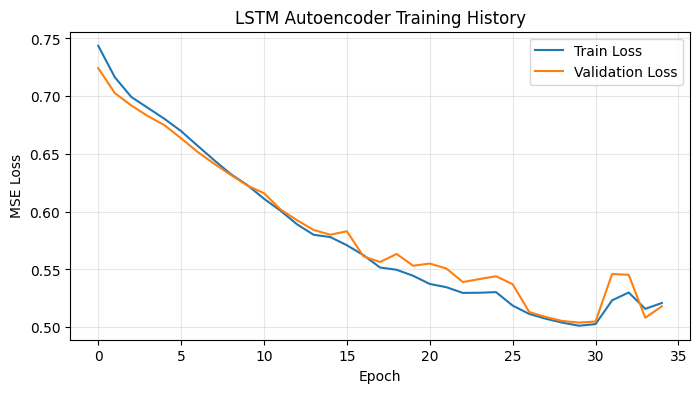

In [ ]:
# If validation loss stops improving, terminate training early to avoid overfitting and save time
early_stop = EarlyStopping(
    monitor='val_loss',     # watch validation loss
    patience=5,              # wait 5 epochs with no improvement before stopping
    restore_best_weights=True  # roll back to the best-performing weights when stopping
)

# During training, store the optimal model checkpoint to disc (in case Colab disconnects)
checkpoint = ModelCheckpoint(
    '/content/best_lstm_autoencoder.keras',  # save path
    monitor='val_loss',                       # save whenever val_loss improves
    save_best_only=True                       # only keep the best version, not every epoch
)

# Teach the autoencoder to rebuild its own input, which is why X and y are identical in this case
history = autoencoder.fit(
    X_train_final, X_train_final,             # input = target = benign sequences (reconstruction task)
    validation_data=(X_val_final, X_val_final),  # validate on held-out benign sequences
    epochs=50,                                 # maximum number of passes over the data
    batch_size=128,                            # number of sequences processed per gradient update
    callbacks=[early_stop, checkpoint],        # attach our callbacks
    verbose=1                                  # print progress per epoch
)

# To visually verify that the model learn correctly (no overfitting), plot training vs. validation loss
plt.figure(figsize=(8, 4))                       # set figure size
plt.plot(history.history['loss'], label='Train Loss')       # training loss curve
plt.plot(history.history['val_loss'], label='Validation Loss')  # validation loss curve
plt.xlabel('Epoch')                              # x-axis label
plt.ylabel('MSE Loss')                           # y-axis label
plt.title('LSTM Autoencoder Training History')   # chart title
plt.legend()                                     # show the legend
plt.grid(alpha=0.3)                              # light grid for readability
plt.show()                                       # render the plot

**10. Determine the Anomaly Threshold and Compute Reconstruction Error**

Anomaly threshold (from 95th percentile of benign val error): 0.748297


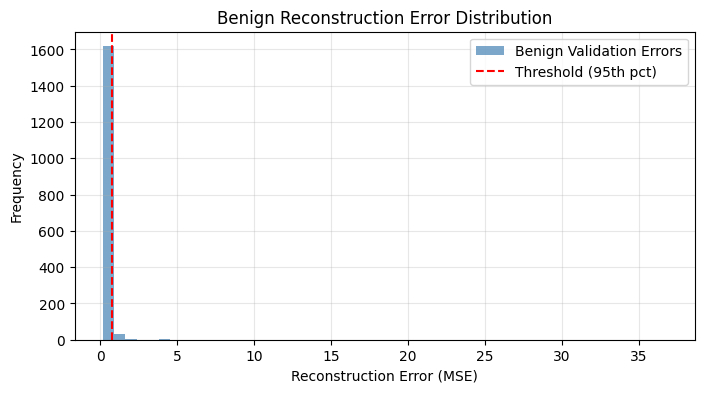

In [ ]:
# Reconstruction error is the degree to which the model's output deviates from the initial input
# Mean Squared Error per sequence (averaged across timestamps + features) is how we quantify this

def compute_reconstruction_error(model, data):
    """
    Runs the model on `data` and returns one MSE value per sequence
    (i.e. how badly the model reconstructed each individual window).
    """
    reconstructed = model.predict(data, verbose=0)          # get the model's reconstructed sequences
    mse_per_sequence = np.mean(np.square(data - reconstructed), axis=(1, 2))  # MSE across timesteps+features
    return mse_per_sequence


# Determine the reconstruction error using our "normal" reference distribution, the BENIGN validation set.
val_errors = compute_reconstruction_error(autoencoder, X_val_final)

# Use a high percentile of the benign validation mistakes to set the anomalous threshold
# Anything that exceeds this threshold will be marked as anomalous
# We tolerate the 5% of benign traffic being identified as a false-positive tradeoff when we use the 95th percentile; adjust this according to your tolerance for false positives
THRESHOLD_PERCENTILE = 95
threshold = np.percentile(val_errors, THRESHOLD_PERCENTILE)

print(f"Anomaly threshold (from {THRESHOLD_PERCENTILE}th percentile of benign val error): {threshold:.6f}")

# Visualize the distribution of benign reconstruction errors with the threshold flagged
plt.figure(figsize=(8, 4))
plt.hist(val_errors, bins=50, color='steelblue', alpha=0.7, label='Benign Validation Errors')
plt.axvline(threshold, color='red', linestyle='--', label=f'Threshold ({THRESHOLD_PERCENTILE}th pct)')
plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Frequency')
plt.title('Benign Reconstruction Error Distribution')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**11. Evaluating on the Full Test Set - Benign and All Attack Types**

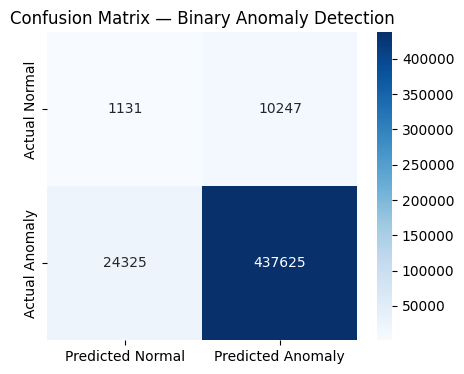

Classification Report (Normal vs Anomaly):
              precision    recall  f1-score   support

      Normal       0.04      0.10      0.06     11378
     Anomaly       0.98      0.95      0.96    461950

    accuracy                           0.93    473328
   macro avg       0.51      0.52      0.51    473328
weighted avg       0.95      0.93      0.94    473328

ROC-AUC Score: 0.5379


In [ ]:
# Compute reconstruction error for EVERY test sequence (benign and attack alike)
test_errors = compute_reconstruction_error(autoencoder, X_test_seq)

# Classify each sequence as anomalous (1) if its error exceeds the threshold, normal (0) otherwise
y_pred = (test_errors > threshold).astype(int)   # model's predicted anomaly flag

# Build the TRUE labels: 0 = Benign, 1 = Anomaly (any of DoS/DDoS/BruteForce/Botnet)
y_true = (test_seq_labels != 'Benign').astype(int)  # ground truth anomaly flag

# The Confusion Matrix
cm = confusion_matrix(y_true, y_pred)  # rows = actual, cols = predicted

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Predicted Normal', 'Predicted Anomaly'],
    yticklabels=['Actual Normal', 'Actual Anomaly']
)
plt.title('Confusion Matrix — Binary Anomaly Detection')
plt.show()

# The Precision / Recall / F1 Report
print("Classification Report (Normal vs Anomaly):")
print(classification_report(y_true, y_pred, target_names=['Normal', 'Anomaly']))

# The ROC-AUC Score
# Rather than using the threshold prediction, it uses raw reconstruction error (continuous score), which indicates how effectively normal and anomalous scores are differentiated regardless of the threshold we have selected
auc = roc_auc_score(y_true, test_errors)
print(f"ROC-AUC Score: {auc:.4f}")


**12. Per-Attack-Type Detection Breakdown**

Benign       | n= 11378 | correct rate: 9.94%
DoS          | n= 83361 | correct rate: 93.03%
DDoS         | n=351049 | correct rate: 94.88%
BruteForce   | n=   132 | correct rate: 87.12%
Botnet       | n= 27408 | correct rate: 98.10%


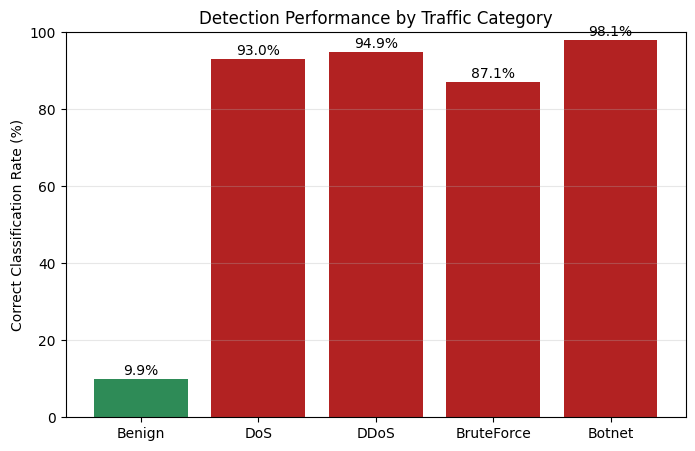

In [ ]:
# One "Normal vs Anomaly" figure conceals a lot; let's test the ability to identify it
# EVERY distinct attack type (DoS, DDoS, Bruteforce, and Botnet separately)

categories_to_check = ['Benign', 'DoS', 'DDoS', 'BruteForce', 'Botnet']  # our 5 target classes

detection_rates = {}  # will store {category: percentage_correctly_classified}

for cat in categories_to_check:
    mask = test_seq_labels == cat # rows belonging to this specific category
    if mask.sum() == 0: # skip if this category doesn't appear in test set
        continue

    cat_errors = test_errors[mask] # reconstruction errors for just this category
    cat_pred   = (cat_errors > threshold).astype(int) # predicted anomaly flags for this category
    if cat == 'Benign':
        # For benign, "correct" means predicted NORMAL (0) — so we report the % correctly kept as normal
        correct_rate = (cat_pred == 0).mean() * 100
    else:
        # For attack categories, "correct" means predicted ANOMALY (1) — this is our detection/recall rate
        correct_rate = (cat_pred == 1).mean() * 100

    detection_rates[cat] = correct_rate
    print(f"{cat:12s} | n={mask.sum():6d} | correct rate: {correct_rate:.2f}%")

# Bar chart visualizing detection rate per category
plt.figure(figsize=(8, 5))
bars = plt.bar(detection_rates.keys(), detection_rates.values(),
                color=['seagreen' if k == 'Benign' else 'firebrick' for k in detection_rates.keys()])
plt.ylabel('Correct Classification Rate (%)')
plt.title('Detection Performance by Traffic Category')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)

# Labelling each bar with it's exact percentage
for bar, value in zip(bars, detection_rates.values()):
    plt.text(bar.get_x() + bar.get_width()/2, value + 1, f'{value:.1f}%', ha='center')

plt.show()

**13. Distribution of Reconstruction Errors by Type of Attack**

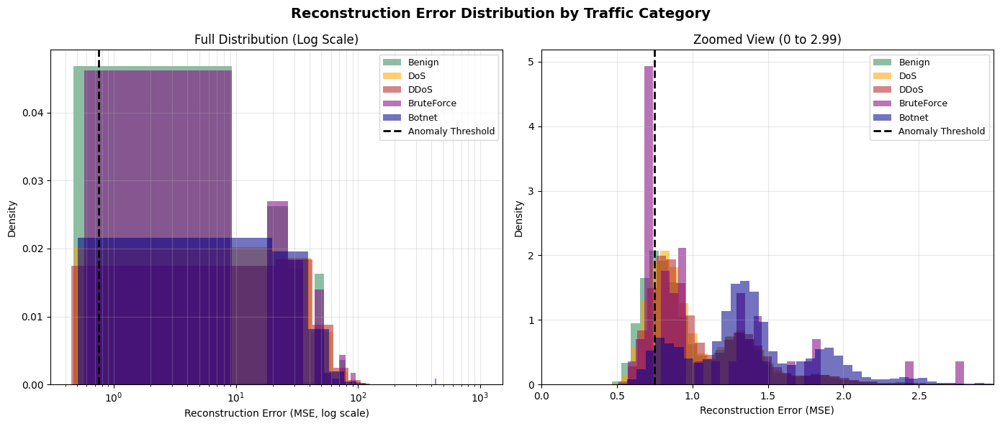

In [ ]:
import matplotlib.pyplot as plt

categories_to_check = ['Benign', 'DoS', 'DDoS', 'BruteForce', 'Botnet']  # our 5 target classes

# Instead of using a single histogram (benign vs. everything), overlay the error distribution for each category
# This provides helpful information for your report on which attack types the model has struggles with, since it illustrates how well-separated each specific type is from regular traffic

fig, (ax_main, ax_zoom) = plt.subplots(1, 2, figsize=(14, 6))  # two side-by-side panels

colors = {'Benign': 'seagreen', 'DoS': 'orange', 'DDoS': 'firebrick',
          'BruteForce': 'purple', 'Botnet': 'darkblue'}  # distinct colour per category

# Small epsilon added before log to avoid log(0) errors on any zero-error sequences
EPS = 1e-6

# ---- LEFT PANEL: full distribution, log-scaled x-axis ----
for cat in categories_to_check:
    mask = test_seq_labels == cat            # boolean mask for this category
    if mask.sum() == 0:                       # skip categories with no samples in this test slice
        continue
    ax_main.hist(
        test_errors[mask] + EPS, bins=50, alpha=0.55, label=cat,
        color=colors.get(cat, 'gray'), density=True
    )

ax_main.axvline(threshold, color='black', linestyle='--', linewidth=2, label='Anomaly Threshold')
ax_main.set_xscale('log')                     # log scale spreads out the crammed low-value detail
ax_main.set_xlabel('Reconstruction Error (MSE, log scale)')
ax_main.set_ylabel('Density')
ax_main.set_title('Full Distribution (Log Scale)')
ax_main.legend(fontsize=9)
ax_main.grid(alpha=0.3, which='both')

# ---- RIGHT PANEL: zoomed-in on the threshold region (linear scale) ----
# Focus the x-range on a window around the threshold so the actual decision boundary
# is clearly visible, rather than dwarfed by outliers.
zoom_upper = threshold * 4  # show up to 4x the threshold value — adjust if your data needs more/less

for cat in categories_to_check:
    mask = test_seq_labels == cat
    if mask.sum() == 0:
        continue
    # Only plot the errors that fall within our zoom window, for a cleaner local view
    zoomed_errors = test_errors[mask]
    zoomed_errors = zoomed_errors[zoomed_errors <= zoom_upper]
    if len(zoomed_errors) == 0:
        continue
    ax_zoom.hist(
        zoomed_errors, bins=40, alpha=0.55, label=cat,
        color=colors.get(cat, 'gray'), density=True
    )

ax_zoom.axvline(threshold, color='black', linestyle='--', linewidth=2, label='Anomaly Threshold')
ax_zoom.set_xlim(0, zoom_upper)
ax_zoom.set_xlabel('Reconstruction Error (MSE)')
ax_zoom.set_ylabel('Density')
ax_zoom.set_title(f'Zoomed View (0 to {zoom_upper:.2f})')
ax_zoom.legend(fontsize=9)
ax_zoom.grid(alpha=0.3)

plt.suptitle('Reconstruction Error Distribution by Traffic Category', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**14. Two-Panel Detection Demo Live Stream**

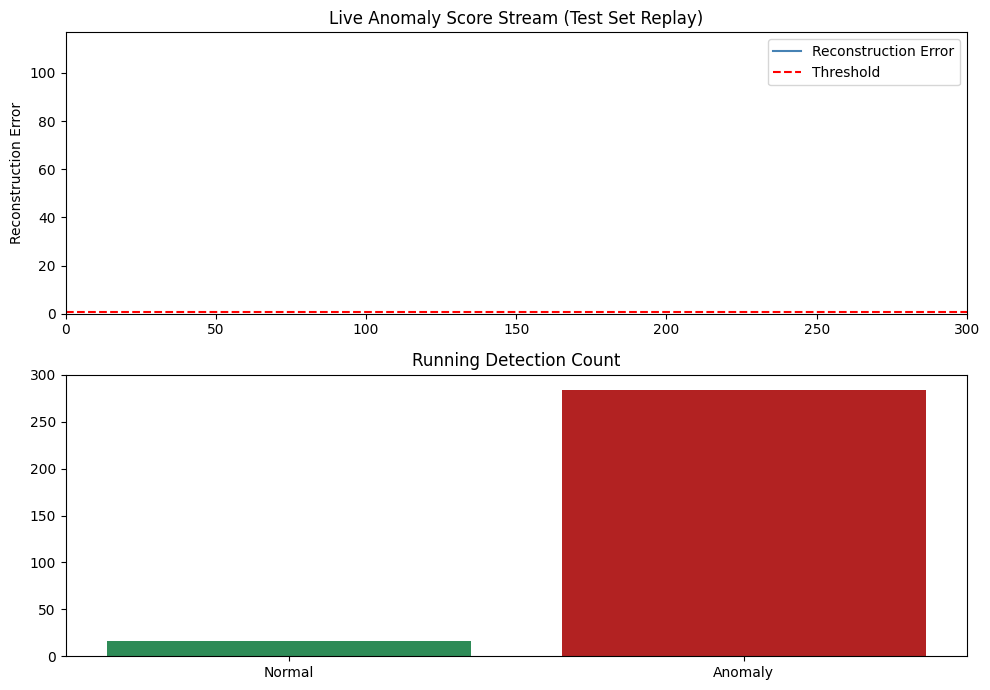

In [ ]:
# Instead of using a single histogram (benign vs everything), overlay the error distribution for each category.
# This provides useful evidence for the report on which attack types the model has trouble with, since it shows how well-separated each particular attack type is from regular traffic
# NOTE: This section is a dataset REPLAY simulation, not a live packet capture (whicb is outside of the scope)

N_DEMO_STEPS = 300               # how many sequences to replay in the demo (keep small for smooth animation)
demo_errors = test_errors[:N_DEMO_STEPS]         # slice the reconstruction errors for the demo window
demo_labels = test_seq_labels[:N_DEMO_STEPS]     # matching ground-truth labels for reference

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7))  # two stacked panels

# Panel 1: The Rolling Error Stream
line, = ax1.plot([], [], color='steelblue', lw=1.5, label='Reconstruction Error')  # error line (empty initially)
threshold_line = ax1.axhline(threshold, color='red', linestyle='--', label='Threshold')  # fixed threshold line
ax1.set_xlim(0, N_DEMO_STEPS)                    # x-axis spans the whole demo
ax1.set_ylim(0, max(demo_errors) * 1.2)          # y-axis padded above the max error value
ax1.set_ylabel('Reconstruction Error')
ax1.set_title('Live Anomaly Score Stream (Test Set Replay)')
ax1.legend(loc='upper right')

# Panel 2: Running Anomaly/Normal Counts
normal_counts = []    # will accumulate running count of normal classifications
anomaly_counts = []   # will accumulate running count of anomaly classifications
bar_normal = ax2.bar(['Normal', 'Anomaly'], [0, 0], color=['seagreen', 'firebrick'])  # initial empty bars
ax2.set_ylim(0, N_DEMO_STEPS)
ax2.set_title('Running Detection Count')

def init():
    """Initializes the animation with empty data."""
    line.set_data([], [])       # clear the error line
    return line, *bar_normal

def update(frame):
    """Called once per animation frame — adds one more data point to the stream."""
    x_data = np.arange(frame + 1)                 # x values up to the current frame
    y_data = demo_errors[:frame + 1]               # corresponding error values up to current frame
    line.set_data(x_data, y_data)

    # Recalculate running normal/anomaly counts up to this frame
    current_preds = (demo_errors[:frame + 1] > threshold).astype(int)  # 1=anomaly, 0=normal
    n_normal = (current_preds == 0).sum()          # count of normal so far
    n_anomaly = (current_preds == 1).sum()         # count of anomaly so far

    bar_normal[0].set_height(n_normal)              # update normal bar height
    bar_normal[1].set_height(n_anomaly)             # update anomaly bar height

    return line, *bar_normal

# Create the animation: one frame per demo sequence, 50ms between frames
anim = animation.FuncAnimation(
    fig, update, frames=N_DEMO_STEPS, init_func=init,
    interval=50, blit=False, repeat=False
)

plt.tight_layout()
HTML(anim.to_jshtml())  # render the animation inline in the Colab output cell